In [17]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

In [2]:
orig_df = pd.read_csv(r'D:\Udemy Courses\complete_data_science_machine_learning_dl_nlp_bootcamp\21-Regression Project\datasets\Algeria_forest_fires_datasets_cleaned_2.csv')
orig_df.head()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,1,6,2012,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,not fire,0
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,not fire,0
4,5,6,2012,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,not fire,0


In [3]:
df = orig_df.drop(['day', 'month', 'year'], axis = 1)
df.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,not fire,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,not fire,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,not fire,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,not fire,0


In [4]:
df['Classes'].value_counts()

Classes
fire        138
not fire    106
Name: count, dtype: int64

In [5]:
df['Classes'] = df['Classes'].apply(lambda x: 0 if x == 'not fire' else 1)
df['Classes'].value_counts()

Classes
1    138
0    106
Name: count, dtype: int64

In [6]:
X = df.drop('FWI', axis = 1)
y = df['FWI']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

In [8]:
X_train.corr()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
Temperature,1.000000,-0.664492,-0.249312,-0.375047,0.703238,0.485379,0.377881,0.609525,0.458575,0.512818,0.256099
RH,-0.664492,1.000000,0.235766,0.262550,-0.637201,-0.398168,-0.218963,-0.694976,-0.344365,-0.429397,-0.397053
Ws,-0.249312,0.235766,1.000000,0.262759,-0.169489,-0.013533,0.075917,0.015384,0.022529,-0.078171,-0.229797
Rain,-0.375047,0.262550,0.262759,1.000000,-0.585018,-0.291338,-0.297047,-0.353219,-0.301347,-0.394262,-0.096985
FFMC,0.703238,-0.637201,-0.169489,-0.585018,1.000000,0.602278,0.510570,0.744270,0.592841,0.774398,0.237434
DMC,0.485379,-0.398168,-0.013533,-0.291338,0.602278,1.000000,0.877718,0.652894,0.981876,0.580530,0.197489
DC,0.377881,-0.218963,0.075917,-0.297047,0.510570,0.877718,1.000000,0.501045,0.941375,0.503725,-0.077220
ISI,0.609525,-0.694976,0.015384,-0.353219,0.744270,0.652894,0.501045,1.000000,0.624038,0.744568,0.267027
BUI,0.458575,-0.344365,0.022529,-0.301347,0.592841,0.981876,0.941375,0.624038,1.000000,0.583094,0.092548
Classes,0.512818,-0.429397,-0.078171,-0.394262,0.774398,0.580530,0.503725,0.744568,0.583094,1.000000,0.158763


In [10]:
X_train.corr().iloc[:3, :2]

,Temperature,RH
Temperature,1.000000,-0.664492
RH,-0.664492,1.000000
Ws,-0.249312,0.235766


In [9]:
def correlation(dataset, threshold):
    col_corr = set()
    corr_matrix = dataset.corr()
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i, j]) > threshold:
                col_name = corr_matrix.columns[i]
                col_corr.add(col_name)
            
    return col_corr

In [11]:
corr_features = correlation(X_train, 0.85)
corr_features

{'BUI', 'DC'}

In [12]:
X_train.drop(corr_features, axis = 1, inplace = True)
X_test.drop(corr_features, axis = 1, inplace = True)

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Linear Regression

In [15]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)
y_pred_test = lin_reg.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred_test)
mae = mean_absolute_error(y_test, y_pred_test)
rmse = np.sqrt(mse)
score = r2_score(y_test, y_pred_test)

print(f"Mean Squared Error : {mse}")
print(f"Mean Absolute Error : {mae}")
print(f"Root Mean Squared Error : {rmse}")
print(f"R2 Score : {score}")

Mean Squared Error : 0.6871108313945653
Mean Absolute Error : 0.6313026202736924
Root Mean Squared Error : 0.8289214868698755
R2 Score : 0.9881381006684763


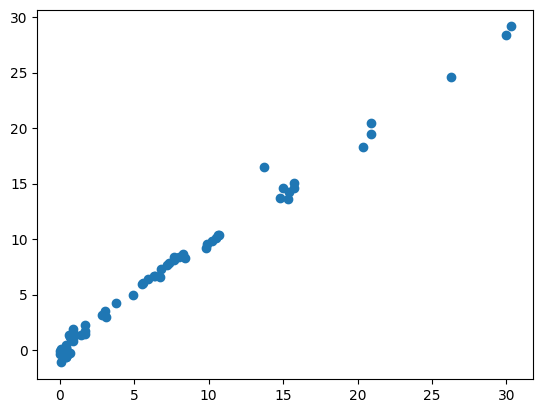

In [18]:
plt.scatter(y_test, y_pred_test)

## Lasso Regression

Mean Squared Error : 2.9732818305580526
Mean Absolute Error : 1.2377413234851184
Root Mean Squared Error : 1.7243206866931837
R2 Score : 0.9486709157433213


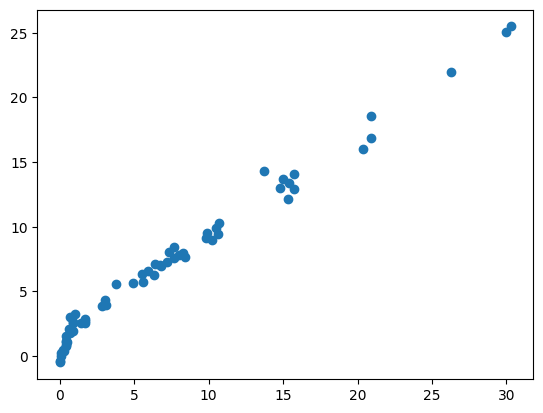

In [19]:
from sklearn.linear_model import Lasso

lasso = Lasso()
lasso.fit(X_train_scaled, y_train)
y_pred_test = lasso.predict(X_test_scaled)

mse = mean_squared_error(y_test, y_pred_test)
mae = mean_absolute_error(y_test, y_pred_test)
rmse = np.sqrt(mse)
score = r2_score(y_test, y_pred_test)

print(f"Mean Squared Error : {mse}")
print(f"Mean Absolute Error : {mae}")
print(f"Root Mean Squared Error : {rmse}")
print(f"R2 Score : {score}")

plt.scatter(y_test, y_pred_test)